# Assignment 3: SLCM Classification Analysis
**CS430 — Aidan Cissell**

Can household and housing information help identify households with $3,000 or more in past-due rent? We train five classifiers on the same prepared data, compare them using accuracy, recall, and F1, and tune KNN and Random Forest with a small GridSearchCV.

## Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, recall_score, f1_score, ConfusionMatrixDisplay

# Part 1 – Understand the Classification Problem

## Question 1: Explore the dataset
Load the CSV. Display five rows, the data shape, the column names, and missing-value counts. Identify one numerical and one categorical feature. Why must `past_due_rent` be excluded from the input features?

In [2]:
df = pd.read_csv("SLCM_rent_arrears_student_clean.csv")
df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [3]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (1754, 14)
Columns: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']


In [4]:
df.isnull().sum()

record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64

In [5]:
df.dtypes

record_id                         str
adults_in_household             int64
children_in_household           int64
household_has_65plus              str
monthly_household_income      float64
income_sources                    str
employment_status                 str
has_housing_voucher               str
eviction_in_progress              str
behind_on_utilities               str
main_reason_behind_on_rent        str
intake_quarter                    str
monthly_rent                  float64
past_due_rent                 float64
dtype: object

**Numerical feature:** monthly_household_income

**Categorical feature:** employment_status

**Answer:** The reason past_due_rent is not included is because high_arrears is made from past_due_rent. If the model can see past_due_rent, it already knows the answer, making the model score perfectly without actually learning from the household and housing information.

## Question 2: Create the target
Create `high_arrears`: 1 if `past_due_rent` is at least $3,000, otherwise 0. Show class counts and one bar chart. Which class is larger? Why might accuracy alone be misleading?

In [6]:
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)

counts = df["high_arrears"].value_counts()
print(counts)
print(df["high_arrears"].value_counts(normalize=True).round(3))

high_arrears
0    1210
1     544
Name: count, dtype: int64
high_arrears
0    0.69
1    0.31
Name: proportion, dtype: float64


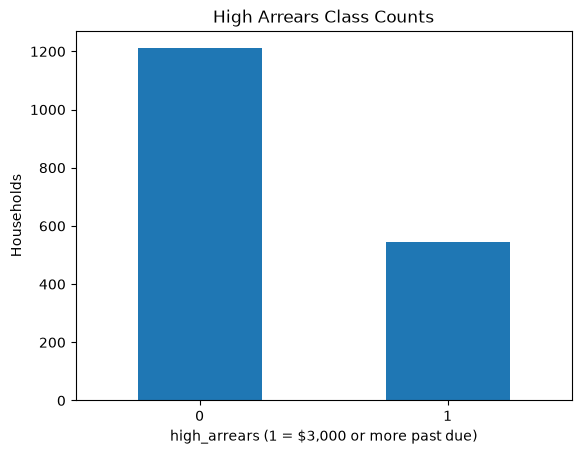

In [7]:
counts.plot(kind="bar")
plt.title("High Arrears Class Counts")
plt.xlabel("high_arrears (1 = $3,000 or more past due)")
plt.ylabel("Households")
plt.xticks(rotation=0)
plt.show()

**Interpretation:** Class 0 is larger with 1,210 households (69%), and class 1 is smaller with 544 households (31%), so the classes are not equal.

**Answer:** Accuracy can be misleading because a model can miss many high-arrears households and still get a high accuracy. For example, if a model predicts 0 for every household, it would still get about 69% accuracy but would miss every high-arrears household, which is the group SLCM cares about most. This is why recall and F1 are more useful here.

# Part 2 – Prepare the Data

## Question 3: Select features and split
Create X by dropping `record_id`, `past_due_rent`, and `high_arrears`. Set y = `high_arrears`. Split the data once into training and testing sets. Why do we keep a separate test set?

In [8]:
x = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", x_train.shape, "Test:", x_test.shape)
print("Training class 1 share:", round(y_train.mean(), 3))
print("Test class 1 share:", round(y_test.mean(), 3))

Training: (1403, 12) Test: (351, 12)
Training class 1 share: 0.31
Test class 1 share: 0.311


**Answer:** We keep a separate test set so the model never sees that data during training. This shows how well the model would do on new households it hasn’t seen before. If we tested on the training data, the scores would look better than they really are because the model could have memorized it (overfitting).

## Question 4: Build one reusable preprocessor
Numerical columns: median imputation and StandardScaler. Categorical columns: most_frequent imputation and OneHotEncoder. Combine with ColumnTransformer. Why is scaling helpful for KNN and SVC?

In [9]:
num_cols = x.select_dtypes(include="number").columns.tolist()
cat_cols = x.select_dtypes(exclude="number").columns.tolist()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)

Numerical: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


In [10]:
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

**Answer:** Scaling helps KNN and SVC because they both work by measuring distance between households. Monthly household income can be in the thousands, while adults in household only goes up to about 5. Without scaling, there is a disparity between the large and small numbers, so income would dominate the distance and adults in household would barely count. Scaling puts them on the same scale so each feature contributes fairly.

# Part 3 – Train and Compare Five Models

## Question 5: Train the five classifiers
Each pipeline uses the same preprocessor and training set. We report test accuracy, recall, and F1 for class 1.

### Logistic Regression

In [11]:
log_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

log_model.fit(x_train, y_train)
log_pred = log_model.predict(x_test)

print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, log_pred), 3))
print("Recall:  ", round(recall_score(y_test, log_pred, zero_division=0), 3))
print("F1:      ", round(f1_score(y_test, log_pred, zero_division=0), 3))

Logistic Regression
Accuracy: 0.695
Recall:   0.303
F1:       0.382


### KNN

In [12]:
knn_model = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(x_train, y_train)
knn_pred = knn_model.predict(x_test)

print("KNN")
print("Accuracy:", round(accuracy_score(y_test, knn_pred), 3))
print("Recall:  ", round(recall_score(y_test, knn_pred, zero_division=0), 3))
print("F1:      ", round(f1_score(y_test, knn_pred, zero_division=0), 3))

KNN
Accuracy: 0.681
Recall:   0.376
F1:       0.423


### Decision Tree

In [13]:
tree_model = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])

tree_model.fit(x_train, y_train)
tree_pred = tree_model.predict(x_test)

print("Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, tree_pred), 3))
print("Recall:  ", round(recall_score(y_test, tree_pred, zero_division=0), 3))
print("F1:      ", round(f1_score(y_test, tree_pred, zero_division=0), 3))

Decision Tree
Accuracy: 0.695
Recall:   0.33
F1:       0.402


### Random Forest

In [14]:
rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)

print("Random Forest")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("Recall:  ", round(recall_score(y_test, rf_pred, zero_division=0), 3))
print("F1:      ", round(f1_score(y_test, rf_pred, zero_division=0), 3))

Random Forest
Accuracy: 0.704
Recall:   0.321
F1:       0.402


### SVC

In [15]:
svc_model = Pipeline([
    ("prep", preprocessor),
    ("model", SVC())
])

svc_model.fit(x_train, y_train)
svc_pred = svc_model.predict(x_test)

print("SVC")
print("Accuracy:", round(accuracy_score(y_test, svc_pred), 3))
print("Recall:  ", round(recall_score(y_test, svc_pred, zero_division=0), 3))
print("F1:      ", round(f1_score(y_test, svc_pred, zero_division=0), 3))

SVC
Accuracy: 0.707
Recall:   0.229
F1:       0.327


**Interpretation:** When running the models, they all had a similar accuracy around 68–71%, which is close to the 69% a model would get by predicting 0 for every household. KNN did the best on recall and F1 but also had the lowest accuracy. SVC had the highest accuracy but caught the fewest high-arrears households.

## Question 6: Compare the models
One results table, and one confusion matrix for the model with the highest test F1. Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

In [16]:
preds = {
    "Logistic Regression": log_pred,
    "KNN": knn_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "SVC": svc_pred
}

results = pd.DataFrame({
    "Model": list(preds.keys()),
    "Accuracy": [round(accuracy_score(y_test, p), 3) for p in preds.values()],
    "Recall": [round(recall_score(y_test, p, zero_division=0), 3) for p in preds.values()],
    "F1": [round(f1_score(y_test, p, zero_division=0), 3) for p in preds.values()]
})

results

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695,0.303,0.382
1,KNN,0.681,0.376,0.423
2,Decision Tree,0.695,0.330,0.402
3,Random Forest,0.704,0.321,0.402
4,SVC,0.707,0.229,0.327


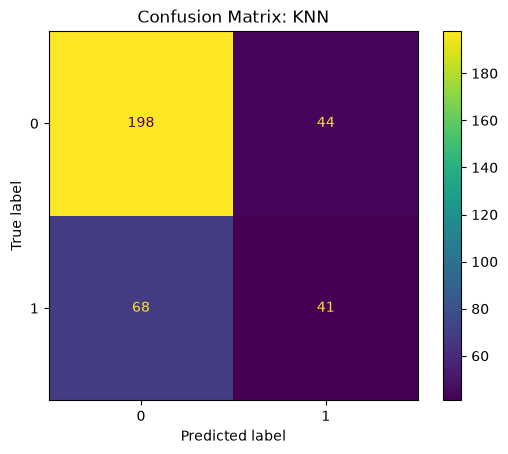

In [17]:
best_model = results.loc[results["F1"].idxmax(), "Model"]

ConfusionMatrixDisplay.from_predictions(y_test, preds[best_model])
plt.title("Confusion Matrix: " + best_model)
plt.show()

**Interpretation:** KNN caught 41 out of 109 high-arrears households but missed 68, so it missed more than it caught. It also flagged 44 households that weren’t actually high-arrears.

**Answer:** The model that catches the highest proportion is KNN, with a recall of 0.376. A missed case for SLCM is a household that is struggling but gets overlooked. The household owes $3,000 or more, but since it isn’t flagged, it might not get help in time, which could lead to eviction.

## Question 7: Try a small GridSearchCV
Tune KNN and Random Forest on the training set with `cv=3` and `scoring="f1"`. The `model__` prefix refers to the model step in each pipeline. The preprocessor is inside the pipeline so it is refit on each fold, which avoids data leakage during cross-validation.

### KNN

In [18]:
knn_tune = Pipeline([
    ("prep", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_grid = {"model__n_neighbors": [3, 5, 7]}

knn_search = GridSearchCV(knn_tune, knn_grid, cv=3, scoring="f1")
knn_search.fit(x_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print("KNN CV F1:", round(knn_search.best_score_, 3))

Best KNN parameters: {'model__n_neighbors': 7}
KNN CV F1: 0.485


### Random Forest

In [19]:
rf_tune = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_grid = {"model__max_depth": [3, 5, None]}

rf_search = GridSearchCV(rf_tune, rf_grid, cv=3, scoring="f1")
rf_search.fit(x_train, y_train)

print("Best RF parameters:", rf_search.best_params_)
print("RF CV F1:", round(rf_search.best_score_, 3))

Best RF parameters: {'model__max_depth': None}
RF CV F1: 0.457


**Answer:** KNN had a higher cross-validation F1 with 0.485, while Random Forest got 0.457. The reason GridSearchCV is fitted on training data only is because it picks the best settings, and the test data needs to stay unseen until the end. If we used the test data to pick the settings, the test data would no longer be new to the model, and the scores would look better than they actually are.

# Part 4 – Explain the Results

## Question 8: Interpret your comparison
In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not accuracy alone. Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

**Answer:** The KNN model is the most promising because it had the highest test F1 (0.423) and recall (0.376), as well as the highest cross-validation F1 after tuning (0.485). Even though KNN had the lowest accuracy, we should not rely on accuracy alone, as shown earlier. More complex models did not necessarily do better, since Random Forest only got 0.402 on F1 and SVC had the lowest recall at 0.229. SLCM should pay attention to false negatives, because even the best model (KNN) still missed 68 of the 109 high-arrears households.

## Question 9: Recommendation to SLCM
Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation. State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

**Answer:** We were trying to predict whether household and housing information can identify households that owe $3,000 or more in past-due rent. The best model found 41 out of 109 high-arrears households (about 4 in 10), which makes it somewhat helpful but not a replacement for the current process. The model could be used as a warning flag to help SLCM decide who to contact before a household’s situation gets worse. One limitation is that it only uses information collected at intake, so it would not see sudden changes like a job loss. A prediction is not proof of what causes high arrears and must not be used alone to decide who gets assistance, so a staff member should still review each household.